<a href="https://colab.research.google.com/github/Lencili/masinsko-ucenje-u-astronomiji/blob/main/PINN_Solver_PyTorch.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# PINN_Solver u PyTorch-u

PyTorch verzija notebook-a [PINN_Solver](https://colab.research.google.com/github/janblechschmidt/PDEsByNNs/blob/main/PINN_Solver.ipynb) (Blechschmidt i Ernst), koji implementira pristup iz rada Raissi, Perdikaris i Karniadakis (2019).

| Deo | Problem | Mreža | Trening |
|---|---|---|---|
| 1 | Burgersova jednačina | 8 × 20, tanh | Adam sa opadajućom stopom učenja |
| 2 | Burgersova jednačina | 8 × 20, tanh | L-BFGS |
| 3 | Eikonalova jednačina | 2 × 20, Leaky ReLU | Adam |
| 4 | Identifikacija parametra λ (inverzni PINN) | 2 × 20, Leaky ReLU | Adam, 1 + 5 ponavljanja |

**Gubitak** (isti u svim delovima):

$$\phi_\theta = \underbrace{\frac{1}{N_r}\sum |r_\theta(t_i^r, x_i^r)|^2}_{\text{rezidual jednačine}} + \underbrace{\frac{1}{N_0}\sum |u_\theta(t_i^0, x_i^0) - u_0|^2}_{\text{početni uslov}} + \underbrace{\frac{1}{N_b}\sum |u_\theta(t_i^b, x_i^b) - u_b|^2}_{\text{granični uslov}}$$

Mreža ima ulaz (t, x) i izlaz u. Svi izvodi se računaju automatskim diferenciranjem (`torch.autograd.grad`).

Na CPU-u ceo notebook traje oko 20–30 minuta, a na GPU-u (Runtime → Change runtime type → T4 GPU) znatno kraće.

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from time import time

torch.manual_seed(0)
np.random.seed(0)
device = 'cuda' if torch.cuda.is_available() else 'cpu'
print('Uređaj:', device)

def izvod(y, x):
    # izvod izlaza y po ulazu x (automatsko diferenciranje); create_graph=True za drugi izvod i trening
    return torch.autograd.grad(y, x, grad_outputs=torch.ones_like(y), create_graph=True)[0]

Uređaj: cpu


---
# Burgersova jednačina

$$
\begin{aligned}
\partial_t u + u\,\partial_x u - \tfrac{0.01}{\pi}\,\partial_{xx} u &= 0, && (t,x) \in (0,1] \times (-1,1)\\
u(0,x) &= -\sin(\pi x), && x \in [-1,1]\\
u(t,-1) = u(t,1) &= 0, && t \in (0,1]
\end{aligned}
$$

Talas koji se usput „strmi“: brži delovi sustižu sporije, pa kod x = 0 nastaje skoro vertikalan skok (udarni talas). Mala viskoznost (0,01/π) ga samo malo zaglađuje.

### 1. Podaci: početni uslov, granice i kolokacione tačke
- **N₀ = 50** tačaka u t = 0, gde je zadato u = −sin(πx);
- **N_b = 50** tačaka na granicama x = ±1, gde je u = 0;
- **N_r = 10 000** kolokacionih tačaka unutar oblasti, gde se proverava jednačina.

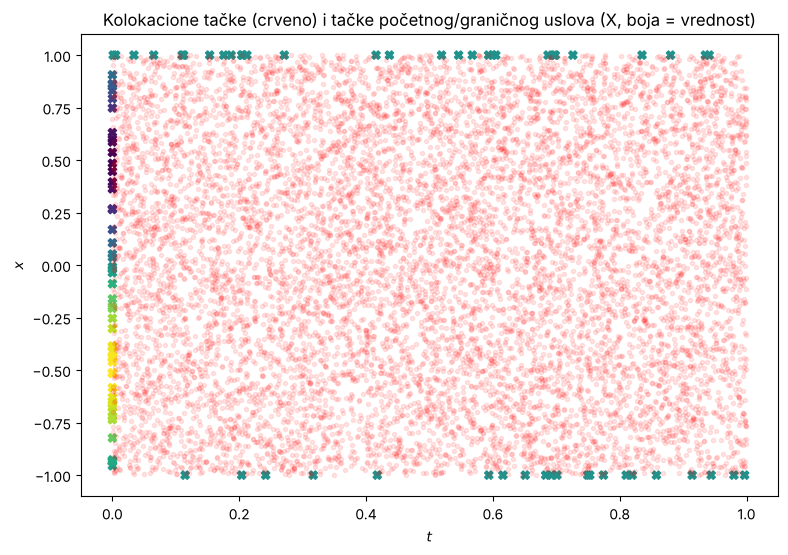

In [ ]:
pi = np.pi
viscosity = 0.01 / pi

N_0, N_b, N_r = 50, 50, 10000
tmin, tmax, xmin, xmax = 0., 1., -1., 1.
lb = torch.tensor([tmin, xmin], device=device)
ub = torch.tensor([tmax, xmax], device=device)

torch.manual_seed(0)

# početni uslov: t = 0
t_0 = torch.full((N_0, 1), tmin)
x_0 = torch.rand(N_0, 1) * (xmax - xmin) + xmin
X_0 = torch.cat([t_0, x_0], dim=1)
u_0 = -torch.sin(pi * x_0)

# granice: x = -1 ili x = 1 (nasumično), t nasumično
t_b = torch.rand(N_b, 1) * (tmax - tmin) + tmin
x_b = xmin + (xmax - xmin) * torch.bernoulli(torch.full((N_b, 1), 0.5))
X_b = torch.cat([t_b, x_b], dim=1)
u_b = torch.zeros(N_b, 1)

# kolokacione tačke
t_r = torch.rand(N_r, 1) * (tmax - tmin) + tmin
x_r = torch.rand(N_r, 1) * (xmax - xmin) + xmin
X_r = torch.cat([t_r, x_r], dim=1)

X_0, u_0, X_b, u_b, X_r = [a.to(device) for a in (X_0, u_0, X_b, u_b, X_r)]
X_data = [X_0, X_b]
u_data = [u_0, u_b]

plt.figure(figsize=(9, 6))
plt.scatter(X_0[:, 0].cpu(), X_0[:, 1].cpu(), c=u_0.cpu(), marker='X', vmin=-1, vmax=1)
plt.scatter(X_b[:, 0].cpu(), X_b[:, 1].cpu(), c=u_b.cpu(), marker='X', vmin=-1, vmax=1)
plt.scatter(X_r[:, 0].cpu(), X_r[:, 1].cpu(), c='r', marker='.', alpha=0.1)
plt.xlabel('$t$'); plt.ylabel('$x$')
plt.title('Kolokacione tačke (crveno) i tačke početnog/graničnog uslova (X, boja = vrednost)')
plt.show()

### 2. Mreža

- ulaz (t, x) se prvo **skalira na [−1, 1]**, jer mreže bolje uče kad su ulazi u istom opsegu;
- **8 skrivenih slojeva po 20 neurona**, tanh;
- jedan izlaz u;
- težine se inicijalizuju Xavier (Glorot) normalnom raspodelom, kao `glorot_normal` u originalu.

Ukupno 3021 parametar: 2·20 + 20 = 60 za prvi sloj, 7 · (20·20 + 20) = 2940 za ostale skrivene i 20 + 1 = 21 za izlaz.

In [ ]:
class PINN_NeuralNet(nn.Module):
    def __init__(self, lb, ub, output_dim=1, num_hidden_layers=8, num_neurons_per_layer=20,
                 activation=None, init='xavier'):
        super().__init__()
        self.lb, self.ub = lb, ub
        activation = activation if activation is not None else nn.Tanh()
        layers, d_in = [], 2
        for _ in range(num_hidden_layers):
            lin = nn.Linear(d_in, num_neurons_per_layer)
            if init == 'xavier':
                nn.init.xavier_normal_(lin.weight)
            else:  # 'he' za Leaky ReLU
                nn.init.kaiming_normal_(lin.weight, a=0.1, nonlinearity='leaky_relu')
            nn.init.zeros_(lin.bias)
            layers += [lin, activation]
            d_in = num_neurons_per_layer
        out = nn.Linear(d_in, output_dim)
        nn.init.xavier_normal_(out.weight); nn.init.zeros_(out.bias)
        layers.append(out)
        self.net = nn.Sequential(*layers)

    def forward(self, X):
        Z = 2.0 * (X - self.lb) / (self.ub - self.lb) - 1.0   # skaliranje na [-1, 1]
        return self.net(Z)

model = PINN_NeuralNet(lb, ub).to(device)
print('Broj parametara:', sum(p.numel() for p in model.parameters()))

Broj parametara: 3021


### 3. Rezidual i gubitak

Rezidual Burgersove jednačine: $r_\theta = \partial_t u_\theta + u_\theta\,\partial_x u_\theta - \tfrac{0.01}{\pi}\,\partial_{xx} u_\theta$

`izvod(u, X)` vraća oba prva izvoda odjednom: kolona 0 je ∂u/∂t, kolona 1 je ∂u/∂x. Za ∂²u/∂x² diferenciramo ∂u/∂x još jednom.

In [ ]:
def fun_r(u, u_t, u_x, u_xx):
    return u_t + u * u_x - viscosity * u_xx

def get_r(model, X_r):
    X = X_r.clone().requires_grad_(True)
    u = model(X)
    du = izvod(u, X)
    u_t, u_x = du[:, 0:1], du[:, 1:2]
    u_xx = izvod(u_x, X)[:, 1:2]
    return fun_r(u, u_t, u_x, u_xx)

def compute_loss(model, X_r, X_data, u_data, get_r=get_r):
    r = get_r(model, X_r)
    loss = torch.mean(r**2)                                  # phi^r
    for X_i, u_i in zip(X_data, u_data):                     # phi^0 i phi^b
        loss = loss + torch.mean((u_i - model(X_i))**2)
    return loss

### 4. Trening: Adam sa opadajućom stopom učenja

$$\delta(n) = 0.01 \text{ za } n < 1000, \quad 0.001 \text{ za } 1000 \le n < 3000, \quad 0.0005 \text{ za } n \ge 3000$$

Veća stopa na početku brzo približi rešenju, a manja kasnije omogućava fino podešavanje.

In [ ]:
def stopa_ucenja(n):
    return 1e-2 if n < 1000 else (1e-3 if n < 3000 else 5e-4)

optim = torch.optim.Adam(model.parameters(), lr=1.0)
scheduler = torch.optim.lr_scheduler.LambdaLR(optim, lr_lambda=stopa_ucenja)

N = 5000
hist = []
t0 = time()
for i in range(N + 1):
    optim.zero_grad()
    loss = compute_loss(model, X_r, X_data, u_data)
    loss.backward()
    optim.step()
    scheduler.step()
    hist.append(loss.item())
    if i % 500 == 0:
        print('It {:05d}: loss = {:10.8e}'.format(i, loss.item()))
print('\nVreme: {:.1f} s'.format(time() - t0))

It 00000: loss = 6.62074924e-01


It 00500: loss = 1.22054517e-01


It 01000: loss = 1.32571522e-03


It 01500: loss = 9.24639520e-04


It 02000: loss = 6.82883954e-04


It 02500: loss = 5.28491393e-04


It 03000: loss = 4.05344763e-04


It 03500: loss = 2.75439146e-04


It 04000: loss = 2.16929751e-04


It 04500: loss = 1.73729335e-04


It 05000: loss = 1.38370582e-04

Vreme: 145.4 s


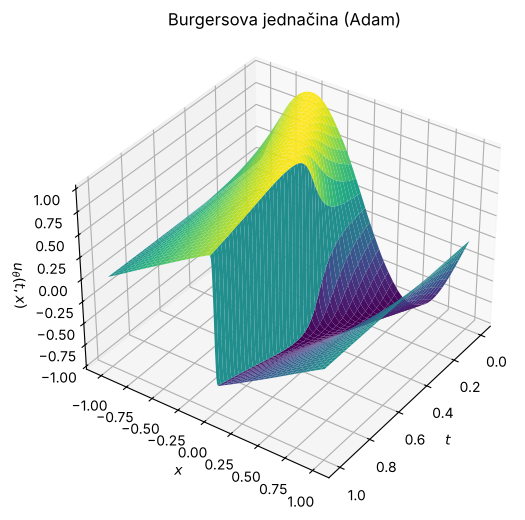

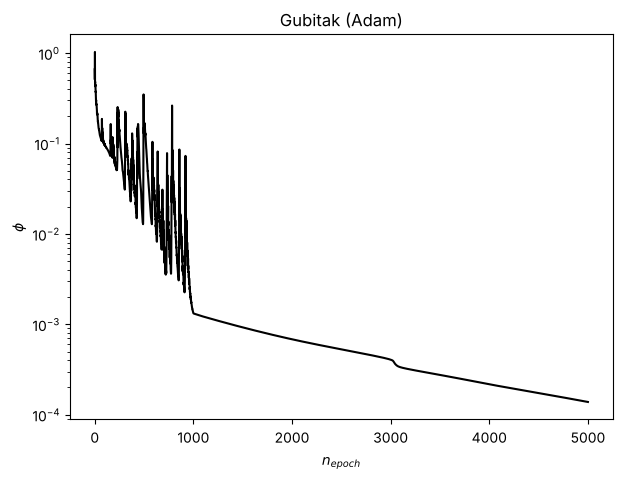

In [ ]:
def nacrtaj_resenje(model, lb, ub, naslov=''):
    N = 300
    tspace = np.linspace(lb[0].item(), ub[0].item(), N + 1)
    xspace = np.linspace(lb[1].item(), ub[1].item(), N + 1)
    T, X = np.meshgrid(tspace, xspace)
    Xgrid = torch.tensor(np.vstack([T.flatten(), X.flatten()]).T, dtype=torch.float32, device=device)
    with torch.no_grad():
        U = model(Xgrid).cpu().numpy().reshape(N + 1, N + 1)
    fig = plt.figure(figsize=(9, 6))
    ax = fig.add_subplot(111, projection='3d')
    ax.plot_surface(T, X, U, cmap='viridis')
    ax.view_init(35, 35)
    ax.set_xlabel('$t$'); ax.set_ylabel('$x$'); ax.set_zlabel(r'$u_\theta(t,x)$')
    ax.set_title(naslov)
    plt.show()

def nacrtaj_gubitak(hist, naslov=''):
    plt.figure(figsize=(7, 5))
    plt.semilogy(hist, 'k-')
    plt.xlabel('$n_{epoch}$'); plt.ylabel(r'$\phi$')
    plt.title(naslov)
    plt.show()

nacrtaj_resenje(model, lb, ub, 'Burgersova jednačina (Adam)')
nacrtaj_gubitak(hist, 'Gubitak (Adam)')

### 5. Isti problem sa L-BFGS

Nova mreža, istrenirana od početka optimizerom L-BFGS. U originalu je korišćen SciPy (`scipy.optimize.minimize`), a ovde `torch.optim.LBFGS`, pa nije potrebna konverzija težina u float64. Ograničili smo broj iteracija na 5000 (u originalu je SciPy stao posle oko 3000).

L-BFGS pored gradijenta procenjuje i zakrivljenost gubitka, pa kod ovakvih problema obično dostiže manji gubitak od Adama.

In [ ]:
torch.manual_seed(0)
model_lbfgs = PINN_NeuralNet(lb, ub).to(device)

optim_lbfgs = torch.optim.LBFGS(model_lbfgs.parameters(), lr=1.0, max_iter=5000, max_eval=6250,
                                history_size=50, tolerance_grad=1e-9,
                                tolerance_change=np.finfo(float).eps, line_search_fn='strong_wolfe')
hist_lbfgs = []

def closure():
    optim_lbfgs.zero_grad()
    loss = compute_loss(model_lbfgs, X_r, X_data, u_data)
    loss.backward()
    hist_lbfgs.append(loss.item())
    if len(hist_lbfgs) % 500 == 0:
        print('Eval {:05d}: loss = {:10.8e}'.format(len(hist_lbfgs), loss.item()))
    return loss

t0 = time()
optim_lbfgs.step(closure)
print('\nKonačan gubitak: {:10.8e}   vreme: {:.1f} s'.format(hist_lbfgs[-1], time() - t0))

Eval 00500: loss = 1.44928950e-03


Eval 01000: loss = 1.73246066e-04


Eval 01500: loss = 6.77916032e-05


Eval 02000: loss = 3.06021284e-05


Eval 02500: loss = 1.89148668e-05



Konačan gubitak: 1.51493768e-05   vreme: 84.4 s


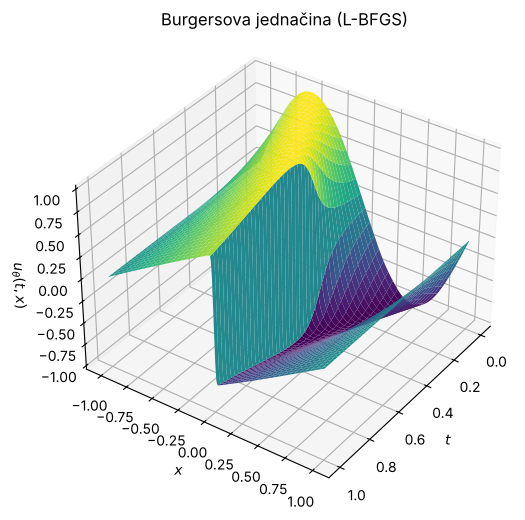

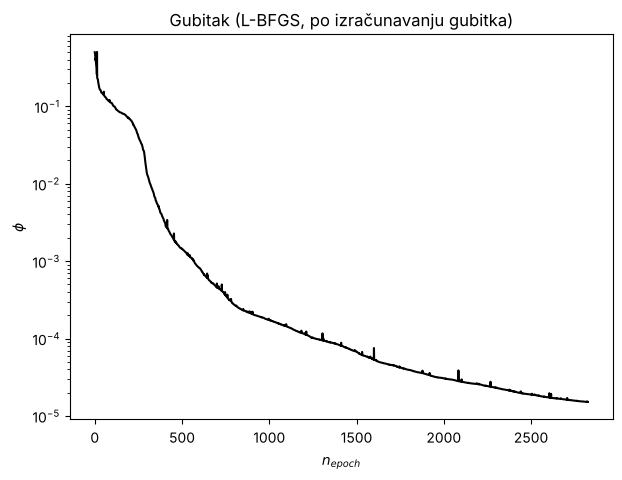

In [ ]:
nacrtaj_resenje(model_lbfgs, lb, ub, 'Burgersova jednačina (L-BFGS)')
nacrtaj_gubitak(hist_lbfgs, 'Gubitak (L-BFGS, po izračunavanju gubitka)')

---
# Eikonalova jednačina (unazad u vremenu)

$$
\begin{aligned}
-\partial_t u + |\partial_x u| &= 1, && (t,x) \in [0,1) \times [-1,1]\\
u(1,x) &= 0, && x \in [-1,1]\\
u(t,-1) = u(t,1) &= 0, && t \in [0,1)
\end{aligned}
$$

Tačno rešenje je $u(t,x) = \min\{1-t,\ 1-|x|\}$: rastojanje od tačke (t, x) do najbliže ivice. Izgleda kao krov sa oštrim grebenom, gde rešenje nema izvod.

Razlike u odnosu na Burgersovu jednačinu:
- uslov je zadat na **kraju** vremena, t = 1;
- jednačina je prvog reda, pa nije potreban drugi izvod;
- zbog oštrih ivica koristi se **Leaky ReLU** (nagib 0,1 za negativne vrednosti) i manja mreža, **2 sloja po 20 neurona**, sa He (Kaiming) inicijalizacijom.

In [ ]:
torch.manual_seed(0)
lb_e = torch.tensor([0., -1.], device=device)
ub_e = torch.tensor([1., 1.], device=device)

t_0e = torch.full((N_0, 1), 1.0)                          # uslov na KRAJU vremena, t = 1
x_0e = torch.rand(N_0, 1) * 2 - 1
X_0e = torch.cat([t_0e, x_0e], dim=1); u_0e = torch.zeros(N_0, 1)

t_be = torch.rand(N_b, 1)
x_be = -1 + 2 * torch.bernoulli(torch.full((N_b, 1), 0.5))
X_be = torch.cat([t_be, x_be], dim=1); u_be = torch.zeros(N_b, 1)

X_re = torch.cat([torch.rand(N_r, 1), torch.rand(N_r, 1) * 2 - 1], dim=1)

X_0e, u_0e, X_be, u_be, X_re = [a.to(device) for a in (X_0e, u_0e, X_be, u_be, X_re)]
X_data_e = [X_0e, X_be]
u_data_e = [u_0e, u_be]

def get_r_eikonal(model, X_r, lambd=None):
    X = X_r.clone().requires_grad_(True)
    u = model(X)
    du = izvod(u, X)
    u_t, u_x = du[:, 0:1], du[:, 1:2]
    desna = 1.0 if lambd is None else 1.0 / lambd
    return -u_t + torch.abs(u_x) - desna

In [ ]:
def stopa_eikonal(n):
    return 1e-1 if n < 3000 else (1e-2 if n < 7000 else 1e-3)

def treniraj_adam(model, X_r, X_data, u_data, get_r, N=10001, ispis=1000, lambd_list=None):
    optim = torch.optim.Adam(model.parameters(), lr=1.0)
    sched = torch.optim.lr_scheduler.LambdaLR(optim, lr_lambda=stopa_eikonal)
    hist = []
    for i in range(N):
        optim.zero_grad()
        loss = compute_loss(model, X_r, X_data, u_data, get_r=get_r)
        loss.backward()
        optim.step(); sched.step()
        hist.append(loss.item())
        if lambd_list is not None:
            lambd_list.append(model.lambd.item())
        if ispis and i % ispis == 0:
            extra = '' if lambd_list is None else '  lambda = {:.6f}'.format(model.lambd.item())
            print('It {:05d}: loss = {:10.8e}{}'.format(i, loss.item(), extra))
    return hist

torch.manual_seed(0)
model_e = PINN_NeuralNet(lb_e, ub_e, num_hidden_layers=2, activation=nn.LeakyReLU(0.1), init='he').to(device)

t0 = time()
hist_e = treniraj_adam(model_e, X_re, X_data_e, u_data_e, get_r=lambda m, X: get_r_eikonal(m, X))
print('\nVreme: {:.1f} s'.format(time() - t0))

It 00000: loss = 1.39987636e+00


It 01000: loss = 1.36617804e-04


It 02000: loss = 4.29397114e-05


It 03000: loss = 4.09983368e-05


It 04000: loss = 3.13741384e-06


It 05000: loss = 2.90265029e-06


It 06000: loss = 2.66923826e-06


It 07000: loss = 6.40456355e-09


It 08000: loss = 4.18605062e-09


It 09000: loss = 2.32424502e-09


It 10000: loss = 4.78300011e-10

Vreme: 37.6 s


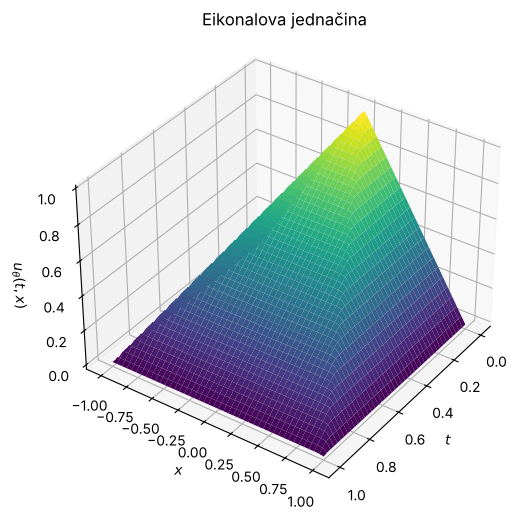

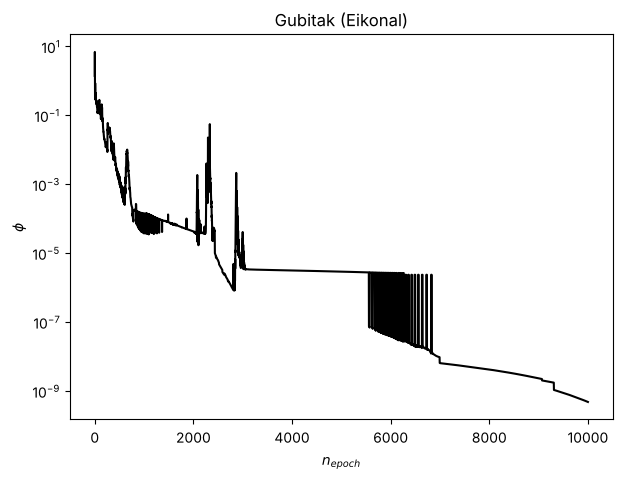

Relativna L2 greška: 0.0015040505


In [ ]:
nacrtaj_resenje(model_e, lb_e, ub_e, 'Eikonalova jednačina')
nacrtaj_gubitak(hist_e, 'Gubitak (Eikonal)')

# poređenje sa tačnim rešenjem
tt, xx = torch.meshgrid(torch.linspace(0, 1, 201), torch.linspace(-1, 1, 201), indexing='ij')
Xg = torch.stack([tt.flatten(), xx.flatten()], dim=1).to(device)
with torch.no_grad():
    u_pred = model_e(Xg).cpu().numpy().ravel()
u_true = np.minimum(1 - tt.flatten().numpy(), 1 - np.abs(xx.flatten().numpy()))
print('Relativna L2 greška:', np.linalg.norm(u_pred - u_true) / np.linalg.norm(u_true))

---
# Identifikacija parametra (inverzni PINN)

$$-\partial_t u + |\partial_x u| = \lambda^{-1}, \qquad u(1,x) = 0, \qquad u(t,\pm 1) = 0$$

Parametar λ **nije poznat**. Tačna vrednost je λ* = 3, a tačno rešenje $u^*(t,x) = \lambda^{-1}\min\{1-t,\ 1-|x|\}$.

- Dodajemo **N_d = 500 merenja** tačnog rešenja na nasumičnim mestima. U gubitak ulaze isto kao početni i granični uslovi.
- λ je `nn.Parameter` u modelu, pa ga optimizer uči **zajedno sa težinama**. Početna vrednost je λ = 1.

In [ ]:
lambd_star = 3.0

def u_expl(t, x, lambd_star):
    return (1.0 / lambd_star) * torch.minimum(1 - t, 1 - torch.abs(x))

torch.manual_seed(1)
N_d = 500
t_d = torch.rand(N_d, 1); x_d = torch.rand(N_d, 1) * 2 - 1
X_d = torch.cat([t_d, x_d], dim=1).to(device)
u_d = u_expl(t_d, x_d, lambd_star).to(device)

X_param = X_data_e + [X_d]
u_param = u_data_e + [u_d]

class PINNIdentificationNet(PINN_NeuralNet):
    def __init__(self, *args, **kwargs):
        super().__init__(*args, **kwargs)
        self.lambd = nn.Parameter(torch.tensor(1.0))   # nepoznati parametar, uči se

get_r_ident = lambda m, X: get_r_eikonal(m, X, lambd=m.lambd)

It 00000: loss = 1.57251823e+00  lambda = 1.100000


It 01000: loss = 1.84060831e-04  lambda = 3.161360


It 02000: loss = 1.04939434e-04  lambda = 3.028495


It 03000: loss = 4.25197650e-04  lambda = 3.059241


It 04000: loss = 1.50320018e-04  lambda = 3.054344


It 05000: loss = 8.58129497e-05  lambda = 3.036017


It 06000: loss = 4.37438939e-05  lambda = 3.015884


It 07000: loss = 6.95094684e-07  lambda = 2.999503


It 08000: loss = 6.62536593e-07  lambda = 2.999503


It 09000: loss = 6.16074260e-07  lambda = 2.999503


It 10000: loss = 4.40233435e-07  lambda = 2.999583

Vreme: 39.3 s


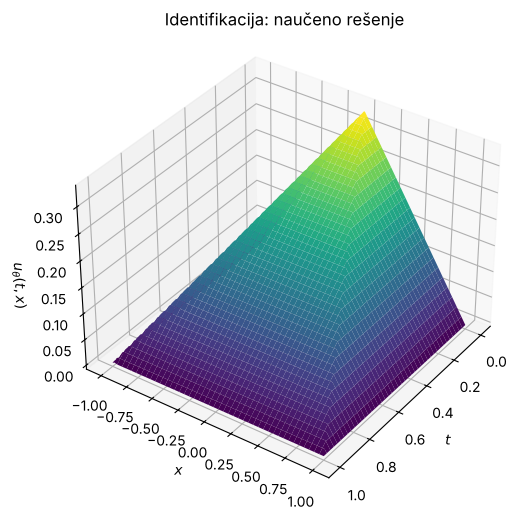

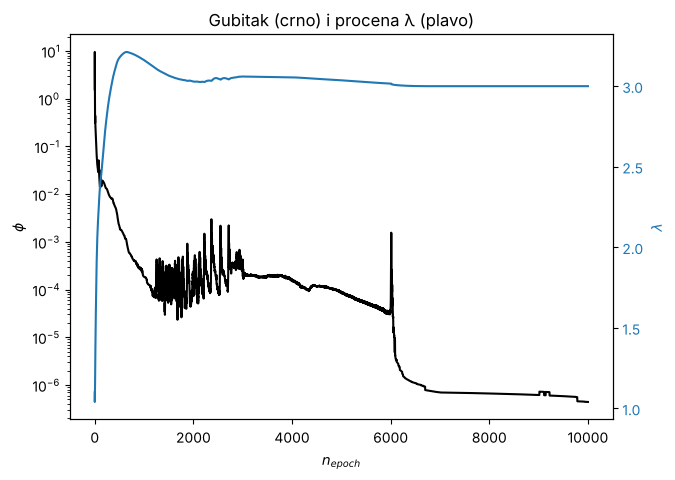

Procenjeno λ = 2.9996,  relativna greška = 0.0139%


In [ ]:
torch.manual_seed(0)
model_id = PINNIdentificationNet(lb_e, ub_e, num_hidden_layers=2, activation=nn.LeakyReLU(0.1), init='he').to(device)
lambd_list = []

t0 = time()
hist_id = treniraj_adam(model_id, X_re, X_param, u_param, get_r=get_r_ident, lambd_list=lambd_list)
print('\nVreme: {:.1f} s'.format(time() - t0))

nacrtaj_resenje(model_id, lb_e, ub_e, 'Identifikacija: naučeno rešenje')

fig, ax1 = plt.subplots(figsize=(7, 5))
ax1.semilogy(hist_id, 'k-'); ax1.set_xlabel('$n_{epoch}$'); ax1.set_ylabel(r'$\phi$')
ax2 = ax1.twinx()
ax2.plot(lambd_list, '-', color='tab:blue'); ax2.set_ylabel(r'$\lambda$', color='tab:blue')
ax2.tick_params(axis='y', labelcolor='tab:blue')
plt.title('Gubitak (crno) i procena λ (plavo)')
plt.show()

print('Procenjeno λ = {:.4f},  relativna greška = {:.4%}'.format(model_id.lambd.item(),
      abs(model_id.lambd.item() - lambd_star) / lambd_star))

### Pet ponavljanja

Težine se svaki put nasumično inicijalizuju, pa ponavljamo trening 5 puta da bismo videli koliko je procena λ pouzdana.

In [ ]:
lambd_hist = []
for k in range(5):
    print('--- Ponavljanje {} ---'.format(k))
    torch.manual_seed(100 + k)
    m = PINNIdentificationNet(lb_e, ub_e, num_hidden_layers=2, activation=nn.LeakyReLU(0.1), init='he').to(device)
    ll = []
    treniraj_adam(m, X_re, X_param, u_param, get_r=get_r_ident, lambd_list=ll, ispis=5000)
    lambd_hist.append(ll)

Lambd = np.array(lambd_hist)
print('\n  korak    srednje λ     std λ')
for i in [1000, 2000, 3000, 4000, 5000, 6000, 7000, 8000, 9000, 10000]:
    print('{:6d}    {:.4f}      {:.4f}'.format(i, Lambd[:, i].mean(), Lambd[:, i].std()))

--- Ponavljanje 0 ---
It 00000: loss = 4.95911503e+00  lambda = 0.900000


It 05000: loss = 2.27657165e-05  lambda = 2.905970


It 10000: loss = 6.83004619e-05  lambda = 2.954805
--- Ponavljanje 1 ---
It 00000: loss = 6.77500534e+00  lambda = 1.100000


It 05000: loss = 8.43944144e-06  lambda = 2.988888


It 10000: loss = 2.24448581e-06  lambda = 2.997374
--- Ponavljanje 2 ---
It 00000: loss = 4.52047014e+00  lambda = 0.900000


It 05000: loss = 6.16524085e-06  lambda = 3.006447


It 10000: loss = 2.70563714e-06  lambda = 2.999321
--- Ponavljanje 3 ---
It 00000: loss = 4.31337023e+00  lambda = 1.100000


It 05000: loss = 2.61216496e-06  lambda = 2.999892


It 10000: loss = 8.34496632e-08  lambda = 2.999544
--- Ponavljanje 4 ---
It 00000: loss = 6.44255400e+00  lambda = 1.100000


It 05000: loss = 6.33129312e-05  lambda = 3.013395


It 10000: loss = 1.20347386e-06  lambda = 2.999871

  korak    srednje λ     std λ
  1000    2.7265      0.1659
  2000    2.9341      0.1336
  3000    2.9799      0.0503
  4000    2.9808      0.0450
  5000    2.9829      0.0393
  6000    2.9848      0.0320
  7000    2.9869      0.0249
  8000    2.9874      0.0236
  9000    2.9884      0.0214
 10000    2.9902      0.0177


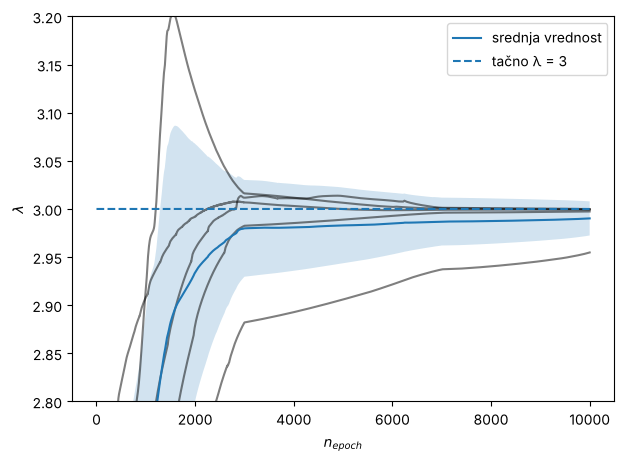

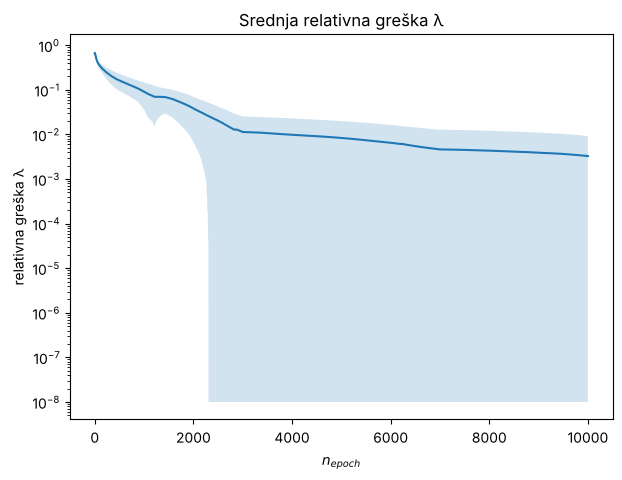

In [ ]:
lmean, lstd = Lambd.mean(axis=0), Lambd.std(axis=0)
rng = range(Lambd.shape[1])

fig, ax = plt.subplots(figsize=(7, 5))
for i in range(len(lambd_hist)):
    ax.plot(rng, lambd_hist[i], '-', color='black', alpha=0.5)
ax.plot(rng, lmean, '-', color='tab:blue', label='srednja vrednost')
ax.plot(rng, lambd_star * np.ones_like(lmean), '--', color='tab:blue', label='tačno λ = 3')
ax.fill_between(rng, lmean - lstd, lmean + lstd, alpha=0.2)
ax.set_ylim([2.8, 3.2]); ax.set_xlabel('$n_{epoch}$'); ax.set_ylabel(r'$\lambda$')
ax.legend()
plt.show()

rel = np.abs((Lambd - lambd_star) / lambd_star)
fig, ax = plt.subplots(figsize=(7, 5))
ax.semilogy(rng, rel.mean(axis=0))
ax.fill_between(rng, np.maximum(rel.mean(axis=0) - rel.std(axis=0), 1e-8), rel.mean(axis=0) + rel.std(axis=0), alpha=0.2)
ax.set_xlabel('$n_{epoch}$'); ax.set_ylabel('relativna greška λ')
ax.set_title('Srednja relativna greška λ')
plt.show()

---
## Zaključak

- **Burgers:** PINN uhvati udarni talas kod x = 0. Adam pri tom osciluje, a L-BFGS je stabilniji i dostiže manji gubitak.
- **Eikonal:** sa Leaky ReLU aktivacijom PINN dobro reprodukuje rešenje sa oštrim grebenom.
- **Inverzni problem:** isti PINN, uz dodata merenja, iz podataka procenjuje nepoznati fizički parametar λ.